# Human tonsil: Fig. 3a-d

RNA, protein and image features lead to the saved 10-domain MELON partition. The archive also contains MELON modality-removal partitions.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/04_Human_tonsil/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "04_Human_tonsil"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Read the saved multimodal result

The three preprocessed AnnData inputs are stored under `02_model_inputs/MELON/`. The code below starts from the existing embedding and final labels.

In [2]:
embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
labels = read_indexed(DATA / "04_clusters/final_clusters.csv")
embedding = align_embedding(embedding, labels)
assert len(labels) == 4194
display(pd.DataFrame({"spots": [len(labels)], "dimensions": [embedding.shape[1]], "domains": [labels.MELON.nunique()]}))

,spots,dimensions,domains
0,4194,128,10


## 2. Display the MELON spatial domains

Use the saved MELON partition and its archived display colors. Cluster IDs remain unchanged.

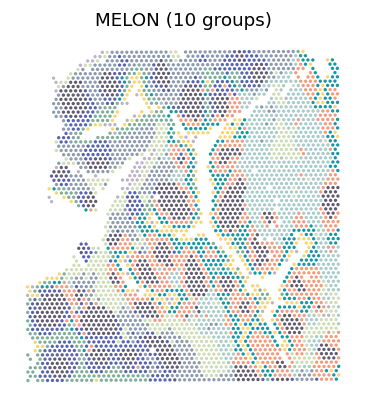

In [3]:
colors = tonsil_colors(DATA)
show(spatial_panels(labels, ["MELON"], colors=colors, ncols=1))

## 3. Display the MELON modality ablations

The full model and each modality-removal variant use their independently saved MELON partitions.

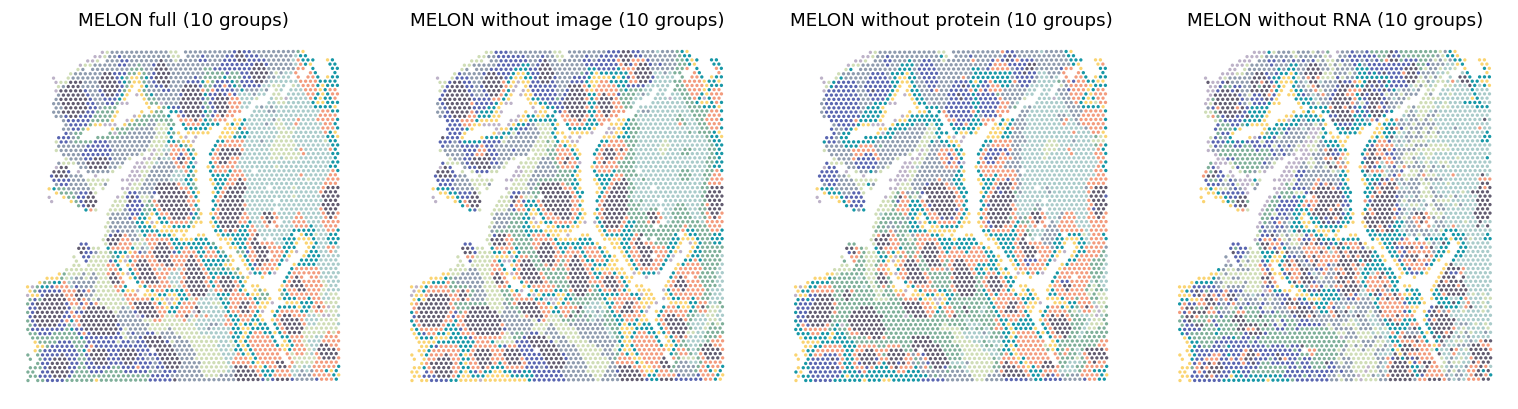

In [4]:
show(spatial_panels(labels, ["Full", "- image", "- protein", "- RNA"], colors=colors, ncols=4))

The saved run records 30 epochs, batch size 4096, spatial k = 6 and seed 42. Additional downstream source tables are listed in [figure sources](../FIGURE_SOURCES.md).